# Exercises week 44: cross-validating your Project 2 network with scikit-learn

**FYS-STK3155/4155 Applied Data Analysis and Machine Learning**

**October 26–30, 2026**

**Deadline: Friday October 30 at midnight** (one notebook per group, in
Canvas).

## Aims of this week's exercises

You have a neural network of your own that fits the Runge function
(Project 2, parts b–d). What you do not yet have is a defensible way of
*choosing* what went into that fit — the learning rate, the regularisation
parameter and, if you wish, the number of hidden units and layers and the
number of epochs — without touching the test set. Every number you report on the test set must
come from a model whose every choice was made on training data alone, and
the way to make those choices is cross-validation (Section 2.12 of the
lecture notes; Section 3.14 did it for Ridge and Lasso in Project 1).

This week you do not write the cross-validation loop yourself. You wrap your
own network in the small interface that `scikit-learn` expects of an
estimator, and then `scikit-learn`'s machinery — `KFold`,
`cross_val_score`, `cross_validate`, `GridSearchCV`, `validation_curve` —
does the folds, the scaling inside the folds, the grid and the bookkeeping
for you, exactly as it would for one of its own models. The same wrapper
works for the MNIST classifier (exercise 3, optional). Writing the
cross-validation loop yourself is **optional** (exercise 4): the end of the
notebook shows how the loop looks when written by hand and checks that it
reproduces `scikit-learn`'s numbers to every digit — try it first, then
compare.

- **Exercise 1** (six short questions) tests whether you know what a
  cross-validation estimate is and what can go wrong with it.
- **Exercise 2** cross-validates your Project 2 regression network: the
  wrapper, the learning rate and penalty, the polynomial benchmark on the
  same folds, and the test set used once; the architecture and the number
  of epochs (parts c and d) are optional.
- **Exercise 3** (optional) does the same for the MNIST classifier with
  stratified folds and the out-of-fold confusion matrix.
- **Exercise 4** (optional) is the cross-validation loop written by hand,
  with the worked solution in the notebook.

**What is required and what is optional.** In this week's exercises and in
Project 2 you are asked to cross-validate the **learning rate $\gamma$ and
the penalty $\lambda$ in front of the $L_2$ or $L_1$ norm**. Cross-validating
the network parameters — the depth, the number of nodes, the activation
function — and the number of epochs is **optional**, both here and in
Project 2. Parts c) and d) of exercise 2 show how it is done with the same
machinery, so that you can do it if you want to; the required parts are
2a, 2b, 2e and 2f.

The network is your Project 2 code (or the week-41 code of the lecture
notebooks); seed 2026 throughout. Cross-validating a network costs $k$
folds times every point of a grid times every epoch, so plan your runs:
on the 100 Runge points everything below takes minutes, on MNIST use the
subset the exercise prescribes.

**Reading:** Sections 2.9–2.12 (generalisation, bias–variance, bootstrap,
cross-validation), 3.14 (choosing a penalty by cross-validation, the
one-standard-error rule) and 8.12 (regularisation and hyperparameters of a
network) of the lecture notes; the `scikit-learn` user guide on
[cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html),
[tuning the hyper-parameters](https://scikit-learn.org/stable/modules/grid_search.html)
and [developing estimators](https://scikit-learn.org/stable/developers/develop.html);
Hastie, Tibshirani and Friedman, Sections 7.10–7.11; Raschka et al.,
Chapter 6.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, RegressorMixin, ClassifierMixin, clone
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import (KFold, StratifiedKFold, cross_val_score, cross_validate,
                                     cross_val_predict, GridSearchCV, validation_curve, learning_curve)
np.random.seed(2026)

# your network from Project 2 goes here (or the week-41 code: create_layers, feed_forward, backpropagation, train, predict)
def create_layers(sizes, hidden_activation="sigmoid", rng=None):
    """A list of (W, b) pairs, W of shape (inputs, outputs) as in the template.

    sizes = [784, 100, 10] gives two layers: 784 -> 100 -> 10.  The weights are
    drawn with the variance of Eq. (8.74) (He) for ReLU and 1/inputs otherwise,
    the biases are set to 0.01 as in the template.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    layers = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        scale = np.sqrt(2.0 / n_in) if hidden_activation == "relu" else np.sqrt(1.0 / n_in)
        W = rng.normal(0.0, scale, (n_in, n_out))
        b = np.zeros(n_out) + 0.01
        layers.append((W, b))
    return layers


def feed_forward(X, layers, hidden_activation="sigmoid", head="mse"):
    """Eq. (8.21) layer by layer, samples in rows.

    Returns the lists z (pre-activations) and a (activations, a[0] = X): every
    one of them is needed on the way back, so the forward pass stores them.
    """
    f, _ = ACTIVATIONS[hidden_activation]
    a, z = [X], []
    for l, (W, b) in enumerate(layers):
        zl = a[-1] @ W + b                       # the template's  x @ w_1 + b_1
        z.append(zl)
        if l == len(layers) - 1:
            a.append(OUTPUT[head](zl))           # the output head
        else:
            a.append(f(zl))
    return z, a



def sigmoid(z):
    """The logistic function, Eq. (8.22), evaluated without overflow."""
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))

def relu(z):
    """Eq. (8.23)."""
    return np.maximum(0.0, z)

def identity(z):
    return z


def softmax(z):
    """Eq. (8.75) with the shift of Eq. (5.30): rows are samples, columns classes."""
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)

def sigmoid_prime(z):
    s = sigmoid(z)
    return s * (1.0 - s)

def relu_prime(z):
    return (z > 0).astype(float)

def identity_prime(z):
    return np.ones_like(z)

ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_prime),
               "relu": (relu, relu_prime),
               "identity": (identity, identity_prime)}

OUTPUT = {"mse": identity, "binary": sigmoid, "softmax": softmax}

def backpropagation(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """Eqs. (8.65)-(8.68) for all samples at once; returns a list of (dW, db) with the shapes of (W, b)."""
    _, fp = ACTIVATIONS[hidden_activation]
    n = X.shape[0]
    z, a = feed_forward(X, layers, hidden_activation, head)
    delta = (a[-1] - Y) / n                      # Eq. (8.69): the same line for all three heads
    grads = [None] * len(layers)
    for l in range(len(layers) - 1, -1, -1):
        W, _ = layers[l]
        dW = a[l].T @ delta                      # Eq. (8.68): outer products, summed over the samples
        dW += 2.0 * lmbd2 * W + lmbd1 * np.sign(W)   # the penalties of Section 8.12 (weights only)
        db = np.sum(delta, axis=0)               # Eq. (8.67)
        grads[l] = (dW, db)
        if l > 0:
            delta = (delta @ W.T) * fp(z[l - 1])     # Eq. (8.66): pull back through W, modulate by f'
    return grads
def cost(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """The cost of Eq. (8.31): data term for the chosen head plus L2 and L1 penalties on the weights."""
    out = predict(X, layers, hidden_activation, head)
    n = X.shape[0]
    if head == "mse":                            # Eq. (8.32)
        data = 0.5 * np.sum((out - Y) ** 2) / n
    elif head == "binary":                       # Eq. (5.13), averaged
        p = np.clip(out, 1e-12, 1 - 1e-12)
        data = -np.mean(Y * np.log(p) + (1 - Y) * np.log(1 - p))
    else:                                        # Eq. (5.28), averaged, one-hot Y
        p = np.clip(out, 1e-12, 1.0)
        data = -np.mean(np.sum(Y * np.log(p), axis=1))
    reg = sum(lmbd2 * np.sum(W ** 2) + lmbd1 * np.sum(np.abs(W)) for W, _ in layers)
    return data + reg
def train(X, Y, layers, hidden_activation="sigmoid", head="mse", gamma=0.1, epochs=100,
          batch_size=None, lmbd2=0.0, lmbd1=0.0, rng=None, X_test=None, y_test=None, verbose=False):
    """Plain gradient descent, Eq. (8.70), on minibatches (batch_size=None: the whole set).

    Returns the trained layers and a history with the training cost after
    every epoch and, when a test set is given, the test accuracy.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    n = X.shape[0]
    M = n if batch_size is None else batch_size
    history = {"cost": [], "test_accuracy": []}
    for epoch in range(epochs):
        order = rng.permutation(n)
        for s in range(0, n, M):
            idx = order[s:s + M]
            grads = backpropagation(X[idx], Y[idx], layers, hidden_activation, head, lmbd2, lmbd1)
            layers = [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, grads)]
        history["cost"].append(cost(X, Y, layers, hidden_activation, head, lmbd2, lmbd1))
        if X_test is not None:
            history["test_accuracy"].append(accuracy(X_test, y_test, layers, hidden_activation, head))
        if verbose:
            msg = f"epoch {epoch + 1:3d}: cost {history['cost'][-1]:.4f}"
            if X_test is not None:
                msg += f"  test accuracy {history['test_accuracy'][-1]:.4f}"
            print(msg)
    return layers, history

def accuracy(X, y, layers, hidden_activation, head):
    """Fraction of correct labels; y holds integer labels for softmax, 0/1 for binary."""
    out = predict(X, layers, hidden_activation, head)
    if head == "softmax":
        return np.mean(np.argmax(out, axis=1) == y)
    return np.mean((out[:, 0] > 0.5) == (y > 0.5))
def predict(X, layers, hidden_activation="sigmoid", head="mse"):
    """The output of the network: a vector of predictions, probabilities, or class probabilities."""
    return feed_forward(X, layers, hidden_activation, head)[1][-1]

## Exercise 1: pencil and paper — what cross-validation estimates, and what can go wrong

**a)** State in one sentence what the $k$-fold cross-validation error
estimates (Section 2.12): the error of *which* model, trained on how much
data, evaluated on what? Why is it an estimate of the generalisation error
of the training *procedure* rather than of the one network you finally
train on all the data?

**b)** With $k$ folds you obtain $k$ numbers $e_1,\dots,e_k$. Give the mean
and its standard error, $\bar e\pm s/\sqrt{k}$, and explain why the $k$
numbers are not independent (two training sets share $(k-2)/(k-1)$ of their
samples), so that this standard error is optimistic. What happens to the
bias and the variance of the estimate as $k$ goes from $2$ to $n$
(leave-one-out)?

**c)** Scaling. You standardise the inputs before training. Explain why the
scaler must be *fitted inside each fold* on the training part only, and name
one concrete number that leaks if it is fitted on all the data first. This
is what a `scikit-learn` `Pipeline` guarantees — say in one sentence how.

**d)** A colleague trains ten networks with ten learning rates, reports the
test MSE of each, and writes "the best learning rate is $0.01$, with a test
MSE of $0.0094$". Name the two things that are wrong with that sentence and
write the honest version of it.

**e)** Early stopping. Explain why the number of epochs is a hyperparameter
like any other, how a validation fold is used to choose it (the epoch at
which the validation error is smallest), and why the training error is
useless for that purpose.

**f)** The one-standard-error rule (Section 3.14). You have the
cross-validated MSE and its standard error for
$\lambda\in\{0,10^{-5},\dots,10^{-2}\}$. State the rule and explain why it
prefers the *more* regularised model among those within one standard error
of the best — and what "more regularised" means for a network when the grid
is over hidden units rather than over $\lambda$.

*Write your answers here (LaTeX in markdown is fine), or attach a scanned
page.*

**a)** The $k$-fold cross-validation error estimates the expected generalisation error of a model produced by the training procedure from a training set of size $n(k - 1)/k$, evaluated on data it has not seen (the validation fold). Because neural networks are trained stochastically, we end up training $k$ different networks. Cross-validation separates the performance and stability of the chosen hyperparameters from the randomness (and potential "luck") of training a single network. In other words, it is the generalisation error of the training procedure that we estimate, not that of the final network we train on all the data *after* cross-validation.

**b)** The mean is

$$
\bar{e} = \frac{1}{k} \sum_{i = 1}^k e_i.
$$

The sample standard deviation is

$$
s = \sqrt{\frac{1}{k - 1} \sum_{i = 1}^k (e_i - \bar{e})^2},
$$

giving the standard error

$$
\frac{s}{\sqrt{k}} = \sqrt{\frac{1}{k(k - 1)} \sum_{i = 1}^k (e_i - \bar{e})^2},
$$

so that we report $\bar e \pm s/\sqrt{k}$. The formula $s/\sqrt{k}$ assumes $k$ independent measurements. Here, however, any two training sets share $(k - 2)/(k - 1)$ of their samples, so the $k$ fitted models, and hence their validation errors, are positively correlated. The variance of $\bar e$ is therefore larger than $s^2/k$, and the standard error is artificially small (optimistic).

As $k$ increases from $2$ to $n$ (leave-one-out), the training sets approach the full dataset ($n(k-1)/k \to n-1$), so the *bias* of the estimate decreases. With $k=2$ each model sees only half the data, and the estimate is pessimistic. The *variance* of the estimate, on the other hand, tends to increase: the $k$ training sets become almost identical, so the $k$ errors are highly correlated and averaging them reduces the variance very little, and each validation fold is small (a single point for leave-one-out), so each $e_i$ is very noisy. The cost also grows linearly with $k$. $k = 5$ or $10$ is the usual compromise.

**c)** The scaler standardises the *inputs* $x$. If it is fitted on the whole dataset before the split, it uses the *global* mean and standard deviation. With equally large folds, the global mean is

$$
\bar{x} = \frac{1}{n}\sum_{i = 1}^n x_i = \frac{k-1}{k}\,\bar{x}_\text{train} + \frac{1}{k}\,\bar{x}_\text{val},
$$

so the transformed training data depend on the mean (and similarly the variance) of the validation fold: $\bar{x}_\text{val}$ leaks into training. The model is then evaluated on data that has already influenced its preprocessing, and the CV error becomes optimistic. A `Pipeline` is cloned and `fit` from scratch in every fold, so `StandardScaler` computes the mean and standard deviation from the training part only (`fit_transform`), and the validation part is only `transform`ed with those numbers.

**d)** There are two problems:

1. **The learning rate was chosen on the test set.** The test set is then used as a validation set, and the smallest of ten noisy test MSEs is biased downwards. $0.0094$ is no longer an unbiased estimate of anything, and it is even below the noise level $\sigma^2 = 0.01$.
2. **There is no uncertainty.** A single train/test split and a single training run give one number per learning rate without an error bar, so we cannot tell whether $0.01$ is really better than its neighbours or just lucky with the split and the random initialisation.

An honest version: "Based on 5-fold cross-validation on the training data, a learning rate of $0.01$ gave the lowest CV MSE, $0.0xx \pm 0.00x$ (mean $\pm$ standard error over the folds; $0.003$ and $0.03$ are within one standard error). The selected model, retrained on all the training data, was evaluated *once* on the independent test set, giving a test MSE of $0.0yy \pm 0.00y$."

**e)** The number of epochs determines when the optimisation stops. Too few epochs give underfitting, and too many may give overfitting. The number of epochs is therefore a hyperparameter that must be tuned like any other. In each fold the validation error is computed after every epoch (or for a range of epoch counts), and the epoch with the lowest (mean) validation error is chosen. The training error is useless for this: the longer the network is trained, the more the training error decreases as the network fits the training data (including its noise), so it would always point to "train forever".

**f)** The one-standard-error rule states:

$$
\lambda_{1SE} = \max\{\lambda : CV_K(\lambda) \leq CV_K(\lambda_{\mathrm{min}}) + SE_K(\lambda_{\mathrm{min}})\},
$$

where $\lambda_{1SE}$ is the most sensible choice of penalty, $CV_K(\lambda)$ is the cross-validation error at penalty $\lambda$ and $SE_K(\lambda_{\mathrm{min}})$ is the standard error at the minimum. Within one standard error of the best model, the differences in performance are indistinguishable from noise. Following Occam's razor we therefore prefer the more regularised (simpler) model, which has lower variance and is less likely to have won by luck. When the grid is over the number of hidden units rather than over a penalty parameter $\lambda$, "more regularised" means a smaller network with fewer hidden units (fewer parameters).

## Exercise 2: your network inside scikit-learn's cross-validation — the Runge regression of Project 2

### a) The wrapper: your network as a scikit-learn estimator

`scikit-learn`'s cross-validation functions do not care how a model is
built; they only call a handful of methods. A class that provides them is an
*estimator*, and `KFold`, `cross_val_score`, `GridSearchCV` and `Pipeline`
accept it like any built-in model. The rules are few:

1. **`__init__` stores its arguments and does nothing else.** Every
   hyperparameter is a keyword argument with a default, stored under *the
   same name* (`self.gamma = gamma`). `BaseEstimator` then provides
   `get_params()` and `set_params()` automatically — this is how
   `GridSearchCV` sets `gamma` and `lmbd` for every point of the grid — and
   `clone()` makes the fresh, untrained copy that every fold starts from.
2. **`fit(X, y)` does all the work** — creates the layers from the seed,
   trains, stores the result in attributes ending in an underscore
   (`self.layers_`) — **and returns `self`.**
3. **`predict(X)` returns a 1D array** for regression; `RegressorMixin`
   then supplies `score()` (the $R^2$), and we will ask for the MSE
   explicitly.

Fill in `fit` and `predict` around your own network (the `...` lines).
Nothing else in this notebook depends on how your network is written.

In [2]:
class NeuralNetRegressor(BaseEstimator, RegressorMixin):
    """Your Project 2 network with the scikit-learn estimator interface."""

    def __init__(self, hidden=(50,), activation="sigmoid", gamma=0.03, lmbd=0.0, epochs=100, batch_size=10, seed=2026):
        # store the hyperparameters under the same names; no computation here
        self.hidden = hidden
        self.activation = activation
        self.gamma = gamma
        self.lmbd = lmbd
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed

    def fit(self, X, y):
        # X has shape (n, 1), y shape (n,): build the layers from self.seed,
        # train with your SGD for self.epochs epochs, store the layers in self.layers_
        sizes = [X.shape[1], *self.hidden, 1]
        layers = create_layers(sizes, self.activation, np.random.default_rng(self.seed))
        self.layers_, self.history_ = train(X, y.reshape(-1, 1), layers, self.activation, "mse", gamma=self.gamma,
                                                  epochs=self.epochs, batch_size=self.batch_size, lmbd2=self.lmbd,
                                                  rng=np.random.default_rng(self.seed))
        return self

    def predict(self, X):
        # the network output as a 1D array of length len(X)
        return predict(X, self.layers_, self.activation, "mse")[:, 0]


# the data of Project 2, part b)
def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)
n = 100
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1
y = runge(x) + rng.normal(0.0, sigma, n)
X = x.reshape(-1, 1)

In [3]:
est = NeuralNetRegressor().fit(X, y)
mse_wrapper = np.mean((est.predict(X) - y) ** 2)
layers = create_layers([1, 50, 1], "sigmoid", np.random.default_rng(2026))
layers, _ = train(X, y.reshape(-1, 1), layers, "sigmoid", "mse", gamma=0.03, epochs=100, batch_size=10, rng=np.random.default_rng(2026))
mse_direct = np.mean((predict(X, layers, "sigmoid", "mse")[:, 0] - y) ** 2)
print(f"training MSE through the wrapper {mse_wrapper:.6f}, through the week-41 loop {mse_direct:.6f}, identical: {np.isclose(mse_wrapper, mse_direct)}")
#print("the parameters GridSearchCV can set:", list(cv_pipeline().get_params().keys())[-7:])

training MSE through the wrapper 0.104858, through the week-41 loop 0.104858, identical: True


**Check the wrapper** before cross-validating anything: `fit` on all
100 points, `predict` on them, and compare the training MSE with the number
your own training loop prints for the same settings — they must agree to
every digit. Then run the three lines below. `KFold(5, shuffle=True,
random_state=2026)` fixes the folds for the whole exercise; the `Pipeline`
puts the scaler *inside* each fold; `cross_val_score` returns one score per
fold, as a negative MSE (`scikit-learn` maximises scores). Report the mean
and the standard error $s/\sqrt{k}$ of the five validation MSEs, and the
training MSEs from `cross_validate(..., return_train_score=True)` next to
them.

In [4]:
cv = KFold(n_splits=5, shuffle=True, random_state=2026)
net = make_pipeline(StandardScaler(), NeuralNetRegressor(hidden=(50,), gamma=0.03, epochs=1000))
scores = -cross_val_score(net, X, y, cv=cv, scoring="neg_mean_squared_error")
print(f"5-fold CV MSE {scores.mean():.4f} +/- {scores.std(ddof=1) / np.sqrt(len(scores)):.4f} (folds: {scores})")
res = cross_validate(net, X, y, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
print(-res["train_score"])
print(f"train MSE {np.mean(-res['train_score']):.4f} +/- {np.std(-res['train_score'], ddof=1) / np.sqrt(5):.4f}")

5-fold CV MSE 0.0334 +/- 0.0053 (folds: [0.03131366 0.04900051 0.01633656 0.03336726 0.0370816 ])


[0.02501519 0.03063449 0.02996285 0.02548352 0.02428651]
train MSE 0.0271 +/- 0.0013


The wrapper gives the same training MSE as the week-41 loop (0.104858), so it works. The 5-fold CV MSE is $0.0334 \pm 0.0053$ and the training MSE is $0.0271 \pm 0.0013$. The training MSE is lower, as expected, but both are quite far above the noise level $\sigma^2 = 0.01$ and the gap between them is small. So the network is underfitting more than overfitting with these settings. The validation MSE varies a lot between the folds (0.016 to 0.049), probably because each fold only has 20 points.

### b) Learning rate and penalty with `GridSearchCV`

`GridSearchCV` takes the pipeline, a grid of parameter values addressed as
`<step name>__<parameter>`, the `cv` object and a scoring rule, fits every
combination on every fold, and stores everything in `cv_results_`
(`mean_test_score`, `std_test_score`, `mean_train_score`, `params`, …).
With `refit=True` (the default) it finally retrains the best combination on
*all* the data and exposes it as `best_estimator_`.

Cross-validate your one-hidden-layer network over
$\gamma\in\{0.001, 0.003, 0.01, 0.03, 0.1\}$ and
$\lambda\in\{0, 10^{-5}, 10^{-4}, 10^{-3}, 10^{-2}\}$ at a fixed
architecture and number of epochs. From `cv_results_` draw the CV MSE as a
heat map (the figure part c) of Project 2 asks for) with the training MSE
next to it; mark the minimum and every cell within one standard error of it
(`std_test_score` is the standard deviation over the folds with `ddof=0`;
the standard error $s/\sqrt{k}$ is `std_test_score / np.sqrt(k - 1)`); apply the one-standard-error rule and state your choice. Note
that `scikit-learn` reports negative MSEs; flip the sign.

[[False False False False False]
 [False False False False False]
 [False False False False False]
 [False False False False False]
 [ True  True  True False False]]
minimum: {'neuralnetregressor__gamma': 0.1, 'neuralnetregressor__lmbd': 0.0} CV MSE 0.0263 +/- 0.0041
1SE choice: gamma = 0.1, lambda = 0.0001, CV MSE 0.0303 +/- 0.0053


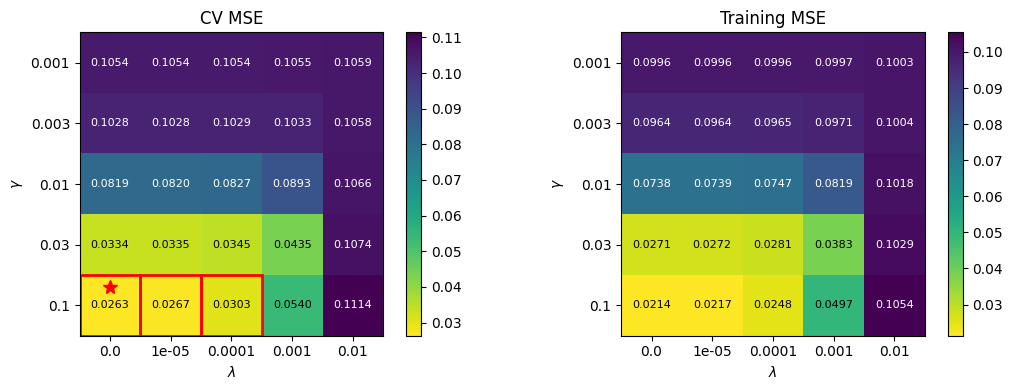

In [5]:
param_grid = {"neuralnetregressor__gamma": [0.001, 0.003, 0.01, 0.03, 0.1],
              "neuralnetregressor__lmbd": [0.0, 1e-5, 1e-4, 1e-3, 1e-2]}
search = GridSearchCV(net, param_grid, cv=cv, scoring="neg_mean_squared_error", return_train_score=True, n_jobs=-1)
search.fit(X, y)
results = search.cv_results_          # a dict of arrays, one entry per grid point
k = 5
gammas = param_grid["neuralnetregressor__gamma"]
lmbds = param_grid["neuralnetregressor__lmbd"]
mse = -results["mean_test_score"].reshape(5, 5)   # rows = gamma, columns = lambda
se = results["std_test_score"].reshape(5, 5) / np.sqrt(k - 1)
tr = -results["mean_train_score"].reshape(5,5)
i_best = np.unravel_index(np.argmin(mse), (5,5))
within = mse <= mse[i_best] + se[i_best]
print(within)
# 1SE rule: largest lambda inside one SE, if several then smallest gamma
cand = [(j, i) for i in range(5) for j in range(5) if within[i, j]]
j1, i1 = max(cand, key=lambda t: (lmbds[t[0]], -gammas[t[1]]))
print("minimum:", search.best_params_, f"CV MSE {mse[i_best]:.4f} +/- {se[i_best]:.4f}")
print(f"1SE choice: gamma = {gammas[i1]}, lambda = {lmbds[j1]}, CV MSE {mse[i1, j1]:.4f} +/- {se[i1, j1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, data, title in zip(ax, [mse, tr], ["CV MSE", "Training MSE"]):
    im = a.imshow(data, cmap="viridis_r")
    for i in range(5):
        for j in range(5):
            a.text(j, i, f"{data[i, j]:.4f}", ha="center", va="center", fontsize=8,
                   color="w" if data[i, j] > data.mean() else "k")
    a.set_xticks(range(5), lmbds)
    a.set_yticks(range(5), gammas)
    a.set_xlabel(r"$\lambda$")
    a.set_ylabel(r"$\gamma$")
    a.set_title(title)
    fig.colorbar(im, ax=a)
# red boxes = within one SE of the minimum, star = minimum
for j, i in cand:
    ax[0].add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="r", lw=2))
ax[0].plot(i_best[1], i_best[0] - 0.3, "r*", ms=10)
plt.tight_layout()
plt.show()

The lowest CV MSE is at $\gamma = 0.1$, $\lambda = 0$: $0.0263 \pm 0.0041$. Within one standard error of this ($\leq 0.0304$) we have $\gamma = 0.1$ with $\lambda = 0, 10^{-5}$ and $10^{-4}$. The one-standard-error rule then gives the largest of these $\lambda$s, so we choose

$\gamma = 0.1$, $\lambda = 10^{-4}$, with CV MSE $0.0303 \pm 0.0053$.

This is the network we use in the rest of the exercise.

The learning rate matters much more than $\lambda$. With $\gamma \leq 0.01$ the network does not get anywhere in 1000 epochs (MSE around 0.08 to 0.1). For $\lambda \geq 10^{-3}$ both the training and the CV MSE go up, so a large penalty just adds bias. That makes sense since the network was not overfitting to begin with, which you can also see from the training MSE being close to the CV MSE everywhere. The minimum is at the edge of the grid (largest $\gamma$), so a larger $\gamma$ or more epochs might be better. We should probably extend the grid in project 2.

### c) Architecture (optional)

Optional here and in Project 2 — the example shows how the architecture is
cross-validated with the same tools. With the $(\gamma,\lambda)$ of b), use `validation_curve` (one parameter,
a range of values, the same `cv`) over the number of hidden units
$\{5, 10, 25, 50, 100\}$ for one hidden layer, and `GridSearchCV` over
`hidden` $\in\{(25,), (25, 25), (25, 25, 25)\}$ for the depth. Plot CV and
training MSE against the number of parameters with error bars. Where does
the training MSE keep falling while the CV MSE does not — and what is that
called (Section 2.10)? Project 2 asks for one and two hidden layers with 50
and 100 nodes: are they distinguishable within the error bars?

5 nodes: CV 0.0248 +/- 0.0025, train 0.0210
10 nodes: CV 0.0288 +/- 0.0040, train 0.0245
25 nodes: CV 0.0300 +/- 0.0035, train 0.0257
50 nodes: CV 0.0303 +/- 0.0053, train 0.0248
100 nodes: CV 0.0280 +/- 0.0031, train 0.0237


(25,), 76 params: CV 0.0300 +/- 0.0035, train 0.0257
(25, 25), 726 params: CV 0.0330 +/- 0.0042, train 0.0280
(25, 25, 25), 1376 params: CV 0.1080 +/- 0.0099, train 0.1026
(50,), 151 params: CV 0.0303 +/- 0.0053, train 0.0248
(100,), 301 params: CV 0.0280 +/- 0.0031, train 0.0237
(50, 50), 2701 params: CV 0.0208 +/- 0.0019, train 0.0173
(100, 100), 10401 params: CV 0.0178 +/- 0.0019, train 0.0149


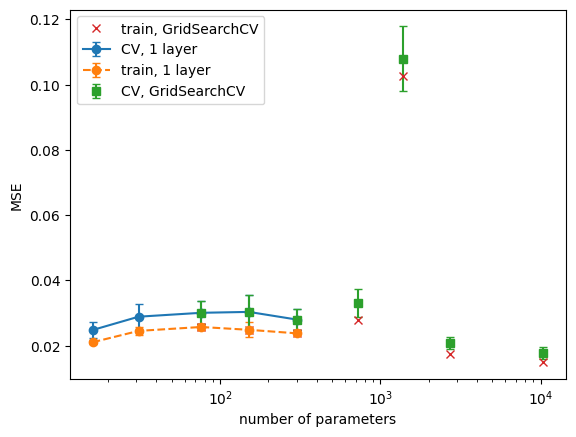

In [6]:
net_c = make_pipeline(StandardScaler(), NeuralNetRegressor(hidden=(50,), gamma=gammas[i1], lmbd=lmbds[j1], epochs=1000))

def count_params(hidden):
    sizes = [1, *hidden, 1]
    return sum((a + 1) * b for a, b in zip(sizes[:-1], sizes[1:]))

widths = [5, 10, 25, 50, 100]
train_scores, val_scores = validation_curve(net_c, X, y, param_name="neuralnetregressor__hidden",
                                            param_range=[(h,) for h in widths], cv=cv,
                                            scoring="neg_mean_squared_error", n_jobs=-1)
val_mse, train_mse = -val_scores, -train_scores
for h, v, t in zip(widths, val_mse, train_mse):
    print(f"{h} nodes: CV {v.mean():.4f} +/- {v.std(ddof=1) / np.sqrt(k):.4f}, train {t.mean():.4f}")

# depth + the 50/100 nodes with 1 and 2 layers from project 2
hidden_grid = [(25,), (25, 25), (25, 25, 25), (50,), (100,), (50, 50), (100, 100)]
search_arch = GridSearchCV(net_c, {"neuralnetregressor__hidden": hidden_grid}, cv=cv,
                           scoring="neg_mean_squared_error", return_train_score=True, n_jobs=-1)
search_arch.fit(X, y)
ra = search_arch.cv_results_
for h, m, s, t in zip(hidden_grid, -ra["mean_test_score"], ra["std_test_score"] / np.sqrt(k - 1), -ra["mean_train_score"]):
    print(f"{h}, {count_params(h)} params: CV {m:.4f} +/- {s:.4f}, train {t:.4f}")

n_par = [count_params((h,)) for h in widths]
p = [count_params(h) for h in hidden_grid]
plt.errorbar(n_par, val_mse.mean(axis=1), val_mse.std(axis=1, ddof=1) / np.sqrt(k), fmt="o-", capsize=3, label="CV, 1 layer")
plt.errorbar(n_par, train_mse.mean(axis=1), train_mse.std(axis=1, ddof=1) / np.sqrt(k), fmt="o--", capsize=3, label="train, 1 layer")
plt.errorbar(p, -ra["mean_test_score"], ra["std_test_score"] / np.sqrt(k - 1), fmt="s", capsize=3, label="CV, GridSearchCV")
plt.plot(p, -ra["mean_train_score"], "x", label="train, GridSearchCV")
plt.xscale("log")
plt.xlabel("number of parameters")
plt.ylabel("MSE")
plt.legend()
plt.show()

For one hidden layer, all widths from 5 to 100 nodes give a CV MSE between about 0.025 and 0.030, with standard errors of 0.003 to 0.005, so we can't really tell them apart. The training MSE doesn't keep going down with more nodes either. The case where the training error keeps falling while the CV error doesn't is overfitting (high variance, Section 2.10), and we don't really get there with 1000 epochs.

Two layers do better: (50, 50) gives $0.0208 \pm 0.0019$ and (100, 100) gives $0.0178 \pm 0.0019$. Three layers of 25 nodes don't work at all (CV MSE 0.108). The training MSE is just as bad there, so this is not overfitting. It is probably vanishing gradients with sigmoid in a deeper network.

For the networks in project 2: 1 layer with 50 vs 100 nodes is not distinguishable within the error bars, and neither is 2 layers with 50 vs 100. One vs two layers is a difference of about 2 standard errors. Part of this is probably that bigger networks train faster in the same number of epochs, not only that they are more flexible.

### d) Epochs, chosen by early stopping (optional)

Optional here and in Project 2. The number of epochs is a hyperparameter. The cheap way with
`scikit-learn` is `validation_curve` over `epochs`
$\in\{50, 100, 200, 500, 1000, 2000\}$ — every value retrains from scratch,
which on 100 points costs seconds. Plot the five per-fold validation curves
and their mean against the number of epochs and choose the number at the
minimum of the mean. How much does the location of the minimum vary between
folds? (If your own `fit` records the validation error after every epoch
you can get the whole curve from one training run per fold — that is how it
is done when training is expensive, and it is worth implementing if you
choose to tune the epochs in Project 2.)

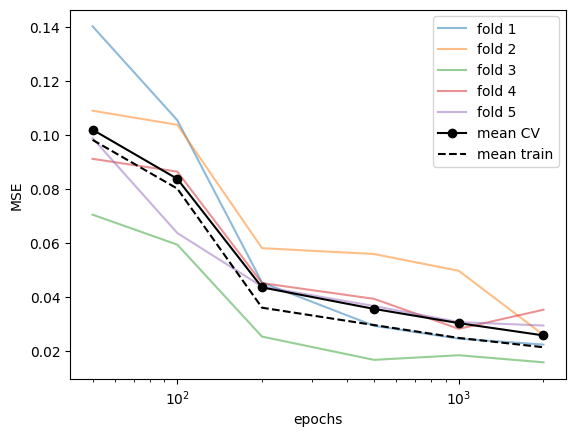

mean CV MSE: [0.1021 0.0838 0.0436 0.0356 0.0303 0.0258]
best number of epochs: 2000
best per fold: [2000, 2000, 2000, 1000, 2000]


In [7]:
epochs = [50, 100, 200, 500, 1000, 2000]
tr_e, val_e = validation_curve(net_c, X, y, param_name="neuralnetregressor__epochs", param_range=epochs,
                               cv=cv, scoring="neg_mean_squared_error", n_jobs=-1)
tr_e, val_e = -tr_e, -val_e     # shape (6, 5)
for f in range(5):
    plt.plot(epochs, val_e[:, f], alpha=0.5, label=f"fold {f + 1}")
plt.plot(epochs, val_e.mean(axis=1), "ko-", label="mean CV")
plt.plot(epochs, tr_e.mean(axis=1), "k--", label="mean train")
plt.xscale("log")
plt.xlabel("epochs")
plt.ylabel("MSE")
plt.legend()
plt.show()
print("mean CV MSE:", np.round(val_e.mean(axis=1), 4))
print("best number of epochs:", epochs[np.argmin(val_e.mean(axis=1))])
print("best per fold:", [epochs[i] for i in np.argmin(val_e, axis=0)])

The mean CV MSE keeps going down over the whole range, from 0.102 at 50 epochs to 0.026 at 2000, so the best number of epochs is 2000 (the edge of the range again). Four of the folds have their minimum at 2000 and one (fold 4) at 1000, where the validation error starts going up a bit. So the minimum doesn't move much between folds.

The training curve follows the CV curve the whole way, so the network is still underfitting and early stopping wouldn't stop anything here. We would need more epochs (or a larger learning rate or a better optimiser) to see the validation curve turn. Going from 1000 to 2000 epochs (0.030 to 0.026) is only about one standard error.

### e) The benchmark: OLS and Ridge on the same folds

Cross-validate `make_pipeline(StandardScaler(), PolynomialFeatures(degree),
LinearRegression())` over degrees $1,\dots,15$ and the Ridge version over
degree and $\lambda$ with `GridSearchCV` on the *same* `cv` object. Put the
best polynomial model and the best network (the one chosen in b), or in
c)–d) if you did them) in one table: CV MSE $\pm$
standard error, number of parameters, fitting time (`cv_results_` has
`mean_fit_time`). Does the network beat the polynomial, and is the
difference larger than the error bars? (Section 8.14 of the notes and the
"What you should take away" list of Project 2 say what to expect.)

In [8]:
poly = make_pipeline(StandardScaler(), PolynomialFeatures(), LinearRegression())
ridge_lambdas=(1e-5, 1e-3, 1e-2, 1)
degrees=range(1,16)
search_poly_ols = GridSearchCV(poly, {"polynomialfeatures__degree": degrees}, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
search_poly_ridge=GridSearchCV(make_pipeline(StandardScaler(), PolynomialFeatures(), Ridge()),{"polynomialfeatures__degree": list(degrees), "ridge__alpha": [len(y) * l for l in ridge_lambdas]},cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
search_poly_ols.fit(X,y)
search_poly_ridge.fit(X,y)
r_ols=search_poly_ols.cv_results_
r_ridge=search_poly_ridge.cv_results_
b_ols = search_poly_ols.best_index_
b_ridge = search_poly_ridge.best_index_
idx_nn = i1 * 5 + j1    # index of the 1SE choice in cv_results_
d=search_poly_ols.best_params_["polynomialfeatures__degree"]
d_r = search_poly_ridge.best_params_["polynomialfeatures__degree"]
print(f"OLS: best degree {d}, CV MSE {-r_ols['mean_test_score'][b_ols]:.4f} +/- {r_ols['std_test_score'][b_ols] / np.sqrt(k - 1):.4f}, {d + 1} parameters, fitting time {r_ols['mean_fit_time'][b_ols]:.4f} s")
print(f"Ridge: {search_poly_ridge.best_params_} (alpha = n lambda), CV MSE {-r_ridge['mean_test_score'][b_ridge]:.4f} +/- {r_ridge['std_test_score'][b_ridge] / np.sqrt(k - 1):.4f}, {d_r + 1} parameters, fitting time {r_ridge['mean_fit_time'][b_ridge]:.4f} s")
print(f"Neural Network: gamma = {gammas[i1]}, lambda = {lmbds[j1]}, CV MSE {mse[i1, j1]:.4f} +/- {se[i1, j1]:.4f}, {count_params((50,))} parameters, fitting time {results['mean_fit_time'][idx_nn]:.4f} s")
# same folds for both, so we can look at the difference fold by fold
nn_folds = np.array([-results[f"split{f}_test_score"][idx_nn] for f in range(k)])
ols_folds = np.array([-r_ols[f"split{f}_test_score"][b_ols] for f in range(k)])
diff = nn_folds - ols_folds
print("NN - OLS per fold:", np.round(diff, 4), f"mean {diff.mean():.4f} +/- {diff.std(ddof=1) / np.sqrt(k):.4f}")

OLS: best degree 11, CV MSE 0.0211 +/- 0.0032, 12 parameters, fitting time 0.0011 s
Ridge: {'polynomialfeatures__degree': 11, 'ridge__alpha': 0.001} (alpha = n lambda), CV MSE 0.0208 +/- 0.0031, 12 parameters, fitting time 0.0011 s
Neural Network: gamma = 0.1, lambda = 0.0001, CV MSE 0.0303 +/- 0.0053, 151 parameters, fitting time 0.6633 s
NN - OLS per fold: [ 0.002   0.0353  0.0014 -0.0047  0.0121] mean 0.0092 +/- 0.0071


| model | CV MSE | parameters | fit time |
|---|---|---|---|
| NN 1-50-1 ($\gamma = 0.1$, $\lambda = 10^{-4}$) | $0.0303 \pm 0.0053$ | 151 | 0.65 s |
| OLS, degree 11 | $0.0211 \pm 0.0032$ | 12 | 0.001 s |
| Ridge, degree 11, $\lambda = 10^{-5}$ | $0.0208 \pm 0.0031$ | 12 | 0.001 s |

The neural network does have a higher MSE than both OLS and Ridge. It also has many more parameters and takes several hundred times longer to fit. Ridge picks the smallest $\lambda$, so it is basically the same as OLS.

The difference is not bigger than the error bars, though. Since all models use the same folds we can look at the difference in each fold: NN minus OLS is $0.0092 \pm 0.0071$, about 1.3 standard errors, and most of it comes from one fold. So the network does not beat the polynomial. For 100 points of a smooth 1D function this is not that surprising. (The (100, 100) network from c) gets 0.0178, slightly better than the polynomial, but with over 10 000 parameters, and that is also within about one standard error.)

### f) The test set, once

Generate a fresh test set of 100 points with a different seed and the same
noise. `search.best_estimator_` is the chosen network retrained on all 100
training points (that is what `refit=True` did); report its test MSE
*once*, next to the cross-validated estimate and its standard error, and do
the same for the polynomial model. Are the test MSEs inside the CV error
bars? Should they be — what does the CV estimate describe, and what does
the test MSE describe (exercise 1a)?

NN test MSE 0.0167 +/- 0.0028
OLS test MSE 0.0159 +/- 0.0025
Ridge test MSE 0.0157 +/- 0.0025


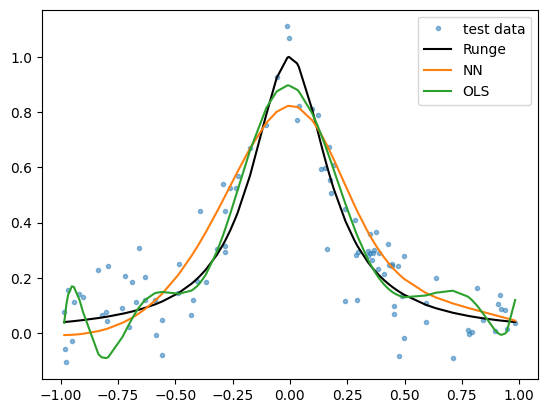

In [9]:
rng_test = np.random.default_rng(2027)
x_test = np.sort(rng_test.uniform(-1.0, 1.0, 100))
y_test = runge(x_test) + rng_test.normal(0.0, sigma, 100)
X_test = x_test.reshape(-1, 1)
# best_estimator_ is the minimum of the grid, we chose the 1SE one so we refit that on all 100 points
nn_final = make_pipeline(StandardScaler(), NeuralNetRegressor(hidden=(50,), gamma=gammas[i1], lmbd=lmbds[j1], epochs=1000)).fit(X, y)
predNN = nn_final.predict(X_test)
predOLS=search_poly_ols.best_estimator_.predict(X_test)
predRidge=search_poly_ridge.best_estimator_.predict(X_test)
for name, pred in [("NN", predNN), ("OLS", predOLS), ("Ridge", predRidge)]:
    err = (pred - y_test) ** 2
    print(f"{name} test MSE {err.mean():.4f} +/- {err.std(ddof=1) / np.sqrt(len(err)):.4f}")

plt.plot(x_test, y_test, ".", alpha=0.5, label="test data")
plt.plot(x_test, runge(x_test), "k", label="Runge")
plt.plot(x_test, predNN, label="NN")
plt.plot(x_test, predOLS, label="OLS")
plt.legend()
plt.show()

Test MSE (100 new points, seed 2027), with standard error = std of the squared errors / $\sqrt{100}$:

- NN: $0.0167 \pm 0.0028$ (CV: $0.0303 \pm 0.0053$)
- OLS: $0.0159 \pm 0.0025$ (CV: $0.0211 \pm 0.0032$)
- Ridge: $0.0157 \pm 0.0025$ (CV: $0.0208 \pm 0.0031$)

All the test MSEs are lower than the CV estimates and outside the CV error bars. On the test set the three models are basically the same.

They don't have to be inside the error bars, since the two numbers are not estimating the same thing (1a). The CV MSE is the error of the training procedure when it trains on 80 points, averaged over the folds. The test MSE is for one specific model trained on all 100 points, measured on one test set that has its own noise. More training data gives a better model. This matters most for the network since it is underfitting: with 100 points it also gets 10 instead of 8 updates per epoch, which is probably why its test MSE drops the most. The CV error bars are also too small, since the folds overlap.

In the plot, the degree-11 polynomial wiggles near the ends ($x = \pm 1$), while the network is smoother but doesn't reach the top of the peak at $x = 0$.

## Exercise 3 (optional): the MNIST classifier of Project 2, part e)

The same wrapper with `ClassifierMixin` instead of `RegressorMixin`:
`fit(X, y)` takes integer labels (one-hot encode them inside `fit`, and set
`self.classes_ = np.unique(y)`), `predict(X)` returns the integer labels
(`np.argmax` of the softmax output) and `predict_proba(X)` the class
probabilities. Use a **stratified subset of 10 000 training images** (1000
per digit) for everything but the last step, `StratifiedKFold(5,
shuffle=True, random_state=2026)` so that every fold has every digit in the
right proportion, and the metric functions of week 43.

**a)** `GridSearchCV` over hidden units $\{32, 64, 128\}$ and learning
rates $\{0.01, 0.03, 0.1\}$ at a fixed number of epochs, `scoring="accuracy"`.
Report CV accuracy $\pm$ standard error and training accuracy for every
cell; which cells are indistinguishable within the error bars? Apply the
one-standard-error rule towards the *smaller* network.

**b)** `cross_val_predict(best, X_sub, y_sub, cv=cv)` gives the
*out-of-fold* prediction of every image — each predicted by a network that
never saw it. Build the $10\times10$ confusion matrix of these predictions
and compare it with the matrix on the official test set (trained on the same
subset). Are the same digit pairs confused? Which matrix belongs in the
report, and why?

**c)** `learning_curve(best, X_sub, y_sub, train_sizes=[1000, 2000, 5000,
8000], cv=cv)`: CV and training accuracy against the training-set size with
error bars. Is the gap closing? Does more data or a larger network look like
the bottleneck, and what do you expect from the full 60 000 images?

**d)** Train the chosen configuration on the full training set and report
the test accuracy with its standard error $\sqrt{\hat p(1-\hat p)/n}$ and
the test confusion matrix, once, as Project 2 asks.

In [10]:
class NeuralNetClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, hidden=(64,), activation="relu", gamma=0.1, lmbd=0.0, epochs=20, batch_size=100, seed=2026):
        self.hidden = hidden
        self.activation = activation
        self.gamma = gamma
        self.lmbd = lmbd
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        ...
        return self

    def predict_proba(self, X):
        ...

    def predict(self, X):
        ...


# data = np.load("mnist.npz")               # see Project 2 for where to get it
# x_train = data["x_train"].reshape(len(data["x_train"]), -1) / 255.0
# y_train = data["y_train"]
# rng = np.random.default_rng(2026)
# sub = np.concatenate([rng.choice(np.where(y_train == c)[0], 1000, replace=False) for c in range(10)])
# X_sub, y_sub = x_train[sub], y_train[sub]
# cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)
...

Ellipsis

## Insights you should have gained this week — a self-check

Before you hand in, go through the list below without looking at the notes.
Each row is a question we may ask in the Tuesday session or on Project 2;
the right-hand column is the insight it tests, in one sentence.

| Ask yourself | The insight it tests |
|---|---|
| What does the $k$-fold CV error estimate? | The expected error of the *training procedure* on unseen data, with training sets of size $n(k-1)/k$ — not the error of the one network you train at the end. |
| Why does the scaler go inside the fold, and how does a `Pipeline` guarantee it? | Fitting it on all the data leaks the validation part's mean and variance into training; a `Pipeline` refits every step on the training part of each fold. |
| What is wrong with "the best learning rate is 0.01, test MSE 0.0094"? | The learning rate was chosen on the test set, so the test MSE no longer estimates anything; choose by CV, then test once. |
| How many numbers does a CV give, and what do you report? | $k$ validation errors: their mean, their standard error $s/\sqrt{k}$ (optimistic, since the folds overlap), and the training error next to them; `std_test_score` is the fold standard deviation (`ddof=0`), not the standard error. |
| What does the one-standard-error rule do? | Among configurations within one standard error of the best, take the simplest (most regularised, fewest units): the data cannot tell them apart. |
| Is the number of epochs a hyperparameter? | Yes: early stopping chooses it at the minimum of the validation curve; the training curve only falls and says nothing. |
| What must a class provide to be a scikit-learn estimator? | An `__init__` that only stores its keyword arguments under the same names, a `fit` that returns `self`, and `predict` (plus `predict_proba` for a classifier); `BaseEstimator` supplies `get_params`/`set_params`, and `clone` gives every fold a fresh copy. |
| What is `best_estimator_`? | The best grid point retrained on all the training data (`refit=True`) — the model to evaluate on the test set, once. |
| What is an out-of-fold prediction, and why build a confusion matrix from it? | Every sample predicted by a model that did not see it (`cross_val_predict`); the matrix then uses all the training data for evaluation and leaves the test set untouched. |
| Why is the best CV score of a grid optimistic? | The minimum of many noisy estimates is biased downward; the test set used once (or nested CV) removes the bias. |

### Practicalities

Deliver your solutions (a single Jupyter notebook) in Canvas before
**Friday October 30 at midnight**. Exercises 1 and 2 are required, except
parts 2c and 2d (architecture and epochs), which are optional; exercises 3
and 4 are optional. Collaboration is encouraged — list your collaborators.
The cross-validation of the learning rate and the penalty in exercise 2 —
the table, the heat map and the test number — is what Project 2 (deadline
**November 6**) requires; cross-validating the depth, the number of nodes
and the epochs is optional there as well. Write the results so that they
can go into the report as they are.

**Declaration of the use of large language models (LLMs).** Many of you use
ChatGPT, Claude, Copilot or similar tools when solving the weekly exercises,
and that is fine — but it has to be declared, for the weekly exercises as
well as for the projects. Add a short paragraph at the end of your notebook
(the cell below is a template) stating which tools you used and for what
(code, debugging, explanations, text), or that you did not use any. A few
sentences are enough; the full guidelines, which you must follow in the
project reports, are at
[LLM_Usage_Declaration_Guidelines.md](https://github.com/EducationalMaterialUiO/MachineLearningUiO/blob/main/LLM_Usage_Declaration_Guidelines.md). Remember that *you* are
responsible for every line you hand in: be prepared to explain it.

## Declaration of the use of LLMs

Tools used: Claude (Anthropic), through Claude Code.

What was done without them:

---

## Exercise 4 (optional): cross-validation written by hand, and checked against scikit-learn

**The exercise.** Write your own `kfold_indices(n, k, rng)` returning $k$
pairs of (training, validation) index arrays, and a loop that, for every
pair, fits the scaler on the training part, trains your network, and
records the validation MSE; check that `mean` and standard error agree with
`cross_validate` on the same index pairs (pass your list of pairs as
`cv=`). Try it before reading on — the rest of this section is the worked
solution, and you may hand it in if you did the exercise.

Everything `scikit-learn` did above is thirty lines of NumPy. We write them
here — the fold indices, the stratified version, the loop with the scaler
fitted inside each fold — and check at every step that the hand-written loop
and `scikit-learn` give the *same* numbers: first on ordinary least squares,
where the fit is deterministic, then on the week-41 network wrapped as the
estimator of exercise 2a. Knowing what the library does is what lets you
read `cv_results_` without guessing, and it is what you will need the day a
problem does not fit the library's assumptions (grouped samples, time
series, a model that must be trained once and evaluated at every epoch).

### The fold indices

`kfold_indices` shuffles $0,\dots,n-1$ once and cuts the permutation into
$k$ nearly equal validation parts, so every sample is validated exactly
once; `stratified_kfold_indices` does the same within each class, so every
fold carries the class proportions of the whole set. The pairs are checked
against `KFold` and `StratifiedKFold`: with the same shuffled permutation
the fold sizes agree, and with `shuffle=False` on an already shuffled array
the index sets agree exactly.

In [11]:
def kfold_indices(n, k, rng):
    """k (train_idx, val_idx) pairs: a shuffled range(n) cut into k nearly equal validation parts."""
    perm = rng.permutation(n)
    sizes = np.full(k, n // k)
    sizes[:n % k] += 1                       # the first n % k folds get one extra sample, as KFold does
    bounds = np.r_[0, np.cumsum(sizes)]
    folds = []
    for i in range(k):
        val = perm[bounds[i]:bounds[i + 1]]
        train = np.concatenate([perm[:bounds[i]], perm[bounds[i + 1]:]])
        folds.append((train, val))
    return folds


def stratified_kfold_indices(y, k, rng):
    """As kfold_indices, but each class is cut into k parts separately, so every fold has the class proportions of y."""
    y = np.asarray(y)
    val_parts = [[] for _ in range(k)]
    for c in np.unique(y):
        idx = rng.permutation(np.where(y == c)[0])
        for i, part in enumerate(np.array_split(idx, k)):
            val_parts[i].append(part)
    folds = []
    for i in range(k):
        val = np.concatenate(val_parts[i])
        train = np.setdiff1d(np.arange(len(y)), val)
        folds.append((train, val))
    return folds


# checks against scikit-learn
n, k = 100, 5
folds = kfold_indices(n, k, np.random.default_rng(2026))
covered = np.sort(np.concatenate([val for _, val in folds]))
print("every index validated exactly once:", np.array_equal(covered, np.arange(n)),
      "; fold sizes", [len(val) for _, val in folds],
      "; KFold sizes", [len(val) for _, val in KFold(k, shuffle=True, random_state=2026).split(np.zeros(n))])
# with shuffle=False, KFold cuts range(n) in order; feeding it our permutation reproduces our folds exactly
perm = np.random.default_rng(2026).permutation(n)
same = all(np.array_equal(perm[v_sk], v_ours) for (_, v_sk), (_, v_ours) in zip(KFold(k).split(np.zeros(n)), folds))
print("identical to KFold(shuffle=False) applied to the same permutation:", same)

y_cls = np.repeat(np.arange(3), [50, 30, 20])          # an imbalanced three-class toy label vector
sfolds = stratified_kfold_indices(y_cls, k, np.random.default_rng(2026))
print("class counts per validation fold (ours):   ", [np.bincount(y_cls[val], minlength=3).tolist() for _, val in sfolds])
print("class counts per validation fold (sklearn):", [np.bincount(y_cls[val], minlength=3).tolist()
                                                     for _, val in StratifiedKFold(k, shuffle=True, random_state=2026).split(np.zeros(len(y_cls)), y_cls)])

every index validated exactly once: True ; fold sizes [20, 20, 20, 20, 20] ; KFold sizes [20, 20, 20, 20, 20]
identical to KFold(shuffle=False) applied to the same permutation: True
class counts per validation fold (ours):    [[10, 6, 4], [10, 6, 4], [10, 6, 4], [10, 6, 4], [10, 6, 4]]
class counts per validation fold (sklearn): [[10, 6, 4], [10, 6, 4], [10, 6, 4], [10, 6, 4], [10, 6, 4]]


### The loop

`cross_validate` takes a `fit_predict(X_tr, y_tr, X_val)` function — train
from scratch on the training part, return predictions on the validation
part — and does the rest: for every fold it fits a scaler on the training
part only, transforms both parts, calls `fit_predict`, and scores the
validation and the training predictions. The two arrays it returns are what
`scikit-learn` stores as `test_score` and `train_score`.

In [12]:
def cross_validate_by_hand(fit_predict, X, y, folds, score, scale=True):
    """One validation score and one training score per fold; the scaler is fitted on the training part of each fold only."""
    val_scores, train_scores = [], []
    for train_idx, val_idx in folds:
        X_tr, X_val = X[train_idx], X[val_idx]
        if scale:
            mean, std = X_tr.mean(axis=0), X_tr.std(axis=0)        # fitted on the training part ...
            X_tr, X_val = (X_tr - mean) / std, (X_val - mean) / std   # ... applied to both
        pred_val, pred_tr = fit_predict(X_tr, y[train_idx], X_val, X_tr)
        val_scores.append(score(y[val_idx], pred_val))
        train_scores.append(score(y[train_idx], pred_tr))
    return np.array(val_scores), np.array(train_scores)


def mse(y_true, y_pred):
    return float(np.mean((y_true - y_pred) ** 2))


def summarise(name, val, train):
    print(f"{name:32s} CV MSE {val.mean():.5f} +/- {val.std(ddof=1) / np.sqrt(len(val)):.5f}   training MSE {train.mean():.5f}   folds {np.round(val, 5)}")

### Check 1: ordinary least squares, where nothing is random

Degree-5 polynomial regression on the Runge data of Project 2, by hand
(`np.linalg.pinv` on the Vandermonde matrix of the *scaled* input) and by
`scikit-learn` (`Pipeline(StandardScaler, PolynomialFeatures,
LinearRegression)`), with the same five folds — our index pairs are passed
to `cross_val_score` as `cv=folds`, which `scikit-learn` accepts. The two
must agree to every digit, and they do.

In [13]:
def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)
x = np.sort(rng.uniform(-1.0, 1.0, 100))
y = runge(x) + rng.normal(0.0, 0.1, 100)
X = x.reshape(-1, 1)
folds = kfold_indices(len(y), 5, np.random.default_rng(2026))


def fit_predict_ols(X_tr, y_tr, X_val, X_tr_again, degree=5):
    V = lambda Z: np.vander(Z[:, 0], degree + 1, increasing=True)       # 1, x, ..., x^degree of the scaled x
    theta = np.linalg.pinv(V(X_tr)) @ y_tr
    return V(X_val) @ theta, V(X_tr_again) @ theta


val_s, train_s = cross_validate_by_hand(fit_predict_ols, X, y, folds, mse)
summarise("OLS degree 5, by hand", val_s, train_s)
pipe = make_pipeline(StandardScaler(), PolynomialFeatures(5), LinearRegression())
res = cross_validate(pipe, X, y, cv=folds, scoring="neg_mean_squared_error", return_train_score=True)
summarise("OLS degree 5, scikit-learn", -res["test_score"], -res["train_score"])
print("identical:", np.allclose(val_s, -res["test_score"]) and np.allclose(train_s, -res["train_score"]))

OLS degree 5, by hand            CV MSE 0.03465 +/- 0.00493   training MSE 0.03026   folds [0.03297 0.03887 0.02144 0.02919 0.05078]
OLS degree 5, scikit-learn       CV MSE 0.03465 +/- 0.00493   training MSE 0.03026   folds [0.03297 0.03887 0.02144 0.02919 0.05078]
identical: True


### Check 2: the week-41 network as the estimator of exercise 2a

The same loop around a network. The cell below is the week-41 code of the
lecture notebooks (`create_layers`, `feed_forward`, `backpropagation`,
`train`, `predict`); the wrapper after it is exercise 2a filled in for that
code — `fit` builds the layers from the seed and trains, `predict` runs the
forward pass. A fresh initialisation with the same seed in every fold makes
the training deterministic, so the hand-written loop and
`cross_val_score` on the pipeline must agree to every digit; they do. The
network is a $1\to50\to1$ sigmoid network trained with SGD for 1000 epochs
at $\gamma=0.03$, deliberately *not* tuned — tuning it is your exercise 2.

In [14]:
def sigmoid(z):
    """The logistic function, Eq. (8.22), evaluated without overflow."""
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


def sigmoid_prime(z):
    s = sigmoid(z)
    return s * (1.0 - s)


def relu(z):
    """Eq. (8.23)."""
    return np.maximum(0.0, z)


def relu_prime(z):
    return (z > 0).astype(float)


def identity(z):
    return z


def identity_prime(z):
    return np.ones_like(z)


def softmax(z):
    """Eq. (8.75) with the shift of Eq. (5.30): rows are samples, columns classes."""
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)



ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_prime),
               "relu": (relu, relu_prime),
               "identity": (identity, identity_prime)}

OUTPUT = {"mse": identity, "binary": sigmoid, "softmax": softmax}


def create_layers(sizes, hidden_activation="sigmoid", rng=None):
    """A list of (W, b) pairs, W of shape (inputs, outputs) as in the template.

    sizes = [784, 100, 10] gives two layers: 784 -> 100 -> 10.  The weights are
    drawn with the variance of Eq. (8.74) (He) for ReLU and 1/inputs otherwise,
    the biases are set to 0.01 as in the template.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    layers = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        scale = np.sqrt(2.0 / n_in) if hidden_activation == "relu" else np.sqrt(1.0 / n_in)
        W = rng.normal(0.0, scale, (n_in, n_out))
        b = np.zeros(n_out) + 0.01
        layers.append((W, b))
    return layers


def feed_forward(X, layers, hidden_activation="sigmoid", head="mse"):
    """Eq. (8.21) layer by layer, samples in rows.

    Returns the lists z (pre-activations) and a (activations, a[0] = X): every
    one of them is needed on the way back, so the forward pass stores them.
    """
    f, _ = ACTIVATIONS[hidden_activation]
    a, z = [X], []
    for l, (W, b) in enumerate(layers):
        zl = a[-1] @ W + b                       # the template's  x @ w_1 + b_1
        z.append(zl)
        if l == len(layers) - 1:
            a.append(OUTPUT[head](zl))           # the output head
        else:
            a.append(f(zl))
    return z, a


def predict(X, layers, hidden_activation="sigmoid", head="mse"):
    """The output of the network: a vector of predictions, probabilities, or class probabilities."""
    return feed_forward(X, layers, hidden_activation, head)[1][-1]


def cost(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """The cost of Eq. (8.31): data term for the chosen head plus L2 and L1 penalties on the weights."""
    out = predict(X, layers, hidden_activation, head)
    n = X.shape[0]
    if head == "mse":                            # Eq. (8.32)
        data = 0.5 * np.sum((out - Y) ** 2) / n
    elif head == "binary":                       # Eq. (5.13), averaged
        p = np.clip(out, 1e-12, 1 - 1e-12)
        data = -np.mean(Y * np.log(p) + (1 - Y) * np.log(1 - p))
    else:                                        # Eq. (5.28), averaged, one-hot Y
        p = np.clip(out, 1e-12, 1.0)
        data = -np.mean(np.sum(Y * np.log(p), axis=1))
    reg = sum(lmbd2 * np.sum(W ** 2) + lmbd1 * np.sum(np.abs(W)) for W, _ in layers)
    return data + reg


def backpropagation(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """Eqs. (8.65)-(8.68) for all samples at once; returns a list of (dW, db) with the shapes of (W, b)."""
    _, fp = ACTIVATIONS[hidden_activation]
    n = X.shape[0]
    z, a = feed_forward(X, layers, hidden_activation, head)
    delta = (a[-1] - Y) / n                      # Eq. (8.69): the same line for all three heads
    grads = [None] * len(layers)
    for l in range(len(layers) - 1, -1, -1):
        W, _ = layers[l]
        dW = a[l].T @ delta                      # Eq. (8.68): outer products, summed over the samples
        dW += 2.0 * lmbd2 * W + lmbd1 * np.sign(W)   # the penalties of Section 8.12 (weights only)
        db = np.sum(delta, axis=0)               # Eq. (8.67)
        grads[l] = (dW, db)
        if l > 0:
            delta = (delta @ W.T) * fp(z[l - 1])     # Eq. (8.66): pull back through W, modulate by f'
    return grads


def train(X, Y, layers, hidden_activation="sigmoid", head="mse", gamma=0.1, epochs=100,
          batch_size=None, lmbd2=0.0, lmbd1=0.0, rng=None, X_test=None, y_test=None, verbose=False):
    """Plain gradient descent, Eq. (8.70), on minibatches (batch_size=None: the whole set).

    Returns the trained layers and a history with the training cost after
    every epoch and, when a test set is given, the test accuracy.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    n = X.shape[0]
    M = n if batch_size is None else batch_size
    history = {"cost": [], "test_accuracy": []}
    for epoch in range(epochs):
        order = rng.permutation(n)
        for s in range(0, n, M):
            idx = order[s:s + M]
            grads = backpropagation(X[idx], Y[idx], layers, hidden_activation, head, lmbd2, lmbd1)
            layers = [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, grads)]
        history["cost"].append(cost(X, Y, layers, hidden_activation, head, lmbd2, lmbd1))
        if X_test is not None:
            history["test_accuracy"].append(accuracy(X_test, y_test, layers, hidden_activation, head))
        if verbose:
            msg = f"epoch {epoch + 1:3d}: cost {history['cost'][-1]:.4f}"
            if X_test is not None:
                msg += f"  test accuracy {history['test_accuracy'][-1]:.4f}"
            print(msg)
    return layers, history


In [15]:
class Week41Regressor(BaseEstimator, RegressorMixin):
    """Exercise 2a, filled in for the week-41 code."""

    def __init__(self, hidden=(50,), activation="sigmoid", gamma=0.03, lmbd=0.0, epochs=1000, batch_size=10, seed=2026):
        self.hidden = hidden
        self.activation = activation
        self.gamma = gamma
        self.lmbd = lmbd
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed

    def fit(self, X, y):
        sizes = [X.shape[1], *self.hidden, 1]
        layers = create_layers(sizes, self.activation, np.random.default_rng(self.seed))
        self.layers_, self.history_ = train(X, y.reshape(-1, 1), layers, self.activation, "mse", gamma=self.gamma,
                                            epochs=self.epochs, batch_size=self.batch_size, lmbd2=self.lmbd,
                                            rng=np.random.default_rng(self.seed))
        return self

    def predict(self, X):
        return predict(X, self.layers_, self.activation, "mse")[:, 0]


def fit_predict_net(X_tr, y_tr, X_val, X_tr_again):
    est = Week41Regressor().fit(X_tr, y_tr)
    return est.predict(X_val), est.predict(X_tr_again)


val_s, train_s = cross_validate_by_hand(fit_predict_net, X, y, folds, mse)
summarise("1-50-1 network, by hand", val_s, train_s)
net = make_pipeline(StandardScaler(), Week41Regressor())
res = cross_validate(net, X, y, cv=folds, scoring="neg_mean_squared_error", return_train_score=True)
summarise("1-50-1 network, scikit-learn", -res["test_score"], -res["train_score"])
print("identical:", np.allclose(val_s, -res["test_score"]) and np.allclose(train_s, -res["train_score"]))
print("the untuned network against degree-5 OLS: CV MSE", f"{val_s.mean():.4f}", "vs", f"{-cross_val_score(pipe, X, y, cv=folds, scoring='neg_mean_squared_error').mean():.4f}",
      "-- the noise level is sigma^2 = 0.01")

1-50-1 network, by hand          CV MSE 0.03026 +/- 0.00443   training MSE 0.02715   folds [0.0293  0.04056 0.02205 0.01926 0.04012]


1-50-1 network, scikit-learn     CV MSE 0.03026 +/- 0.00443   training MSE 0.02715   folds [0.0293  0.04056 0.02205 0.01926 0.04012]
identical: True
the untuned network against degree-5 OLS: CV MSE 0.0303 vs 0.0347 -- the noise level is sigma^2 = 0.01


### A small grid, both ways

Finally the grid search of exercise 2b in miniature — three learning rates,
two penalties — once with two nested loops around `cross_validate_by_hand`
and once with `GridSearchCV`, and the one-standard-error rule applied to
the result. `GridSearchCV` returns exactly the table the loops produce, plus
`best_estimator_`, the winner retrained on all 100 points. One detail
worth knowing: `std_test_score` is the standard deviation over the folds
with `ddof=0`, so the standard error $s/\sqrt{k}$ with the sample standard
deviation $s$ is `std_test_score / np.sqrt(k - 1)`.

In [16]:
gammas, lambdas = [0.01, 0.03, 0.1], [0.0, 1e-3]
table = np.zeros((len(gammas), len(lambdas)))
table_se = np.zeros_like(table)
for i, g in enumerate(gammas):
    for j, l in enumerate(lambdas):
        fp = lambda X_tr, y_tr, X_val, X_tr2, g=g, l=l: (lambda est: (est.predict(X_val), est.predict(X_tr2)))(Week41Regressor(gamma=g, lmbd=l).fit(X_tr, y_tr))
        v, _ = cross_validate_by_hand(fp, X, y, folds, mse)
        table[i, j], table_se[i, j] = v.mean(), v.std(ddof=1) / np.sqrt(len(v))
print("by hand, CV MSE (rows gamma, columns lambda):\n", np.round(table, 5))

search = GridSearchCV(net, {"week41regressor__gamma": gammas, "week41regressor__lmbd": lambdas},
                      cv=folds, scoring="neg_mean_squared_error", return_train_score=True)
search.fit(X, y)
grid = -search.cv_results_["mean_test_score"].reshape(len(gammas), len(lambdas))
grid_se = search.cv_results_["std_test_score"].reshape(len(gammas), len(lambdas)) / np.sqrt(len(folds) - 1)   # std_test_score has ddof=0
print("GridSearchCV, CV MSE:\n", np.round(grid, 5), "\nidentical:", np.allclose(table, grid) and np.allclose(table_se, grid_se))
print("best:", search.best_params_, f"CV MSE {-search.best_score_:.5f} +/- {grid_se.ravel()[search.best_index_]:.5f}")
within = grid <= grid.min() + grid_se.ravel()[search.best_index_]
print("within one standard error of the best (rows gamma, columns lambda):\n", within)
print("the one-standard-error rule picks the most regularised of these: lambda =", max(l for j, l in enumerate(lambdas) if within[:, j].any()),
      "-- and best_estimator_ is the winner retrained on all 100 points:", type(search.best_estimator_[-1]).__name__,
      search.best_estimator_[-1].get_params())

by hand, CV MSE (rows gamma, columns lambda):
 [[0.07723 0.08554]
 [0.03026 0.04077]
 [0.02292 0.04587]]


GridSearchCV, CV MSE:
 [[0.07723 0.08554]
 [0.03026 0.04077]
 [0.02292 0.04587]] 
identical: True
best: {'week41regressor__gamma': 0.1, 'week41regressor__lmbd': 0.0} CV MSE 0.02292 +/- 0.00345
within one standard error of the best (rows gamma, columns lambda):
 [[False False]
 [False False]
 [ True False]]
the one-standard-error rule picks the most regularised of these: lambda = 0.0 -- and best_estimator_ is the winner retrained on all 100 points: Week41Regressor {'activation': 'sigmoid', 'batch_size': 10, 'epochs': 1000, 'gamma': 0.1, 'hidden': (50,), 'lmbd': 0.0, 'seed': 2026}


Six grid points move the network from $0.030$ to $0.023$ — below the
degree-5 polynomial's $0.035$ and within a factor of two of the noise
floor $\sigma^2=0.01$; the rest of the way, with error bars, is
exercise 2.

That is all a cross-validation is: a permutation cut into $k$ pieces, a
scaler fitted $k$ times, a model trained $k$ times from scratch, and $k$
numbers summarised by their mean and standard error. `scikit-learn` adds
the bookkeeping, the parallelism (`n_jobs`), the refit, and — not least —
the guarantee that the scaler never sees the validation fold. Use the
library in Project 2; keep this section for the day you need to know what
it did.